Device: mps
HAM10000: 10015
label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Train 7153 | Val 1431 | Test 1431 (no shared lesions)
Class weights: {'akiec': np.float32(4.3669), 'bcc': np.float32(2.792), 'bkl': np.float32(1.3017), 'df': np.float32(12.4617), 'mel': np.float32(1.2854), 'nv': np.float32(0.2134), 'vasc': np.float32(10.0182)}
[Stage 1] Epoch 01/50 | train 2.0694 | val 0.8587 | val_acc 0.1775 | 80s *saved*
[Stage 1] Epoch 02/50 | train 1.3583 | val 0.8664 | val_acc 0.1775 | 81s
[Stage 1] Epoch 03/50 | train 1.1605 | val 0.9125 | val_acc 0.2369 | 84s *saved*
[Stage 1] Epoch 04/50 | train 1.0367 | val 1.0084 | val_acc 0.2257 | 85s
[Stage 1] Epoch 05/50 | train 0.9214 | val 0.9762 | val_acc 0.3305 | 84s *saved*
[Stage 1] Epoch 06/50 | train 0.8321 | val 0.8728 | val_acc 0.3599 | 84s *saved*
[Stage 1] Epoch 07/50 | train 0.7538 | val 1.0619 | val_acc 0.3704 | 87s *saved*
[Stage 1] Epoch 08/50 | train 

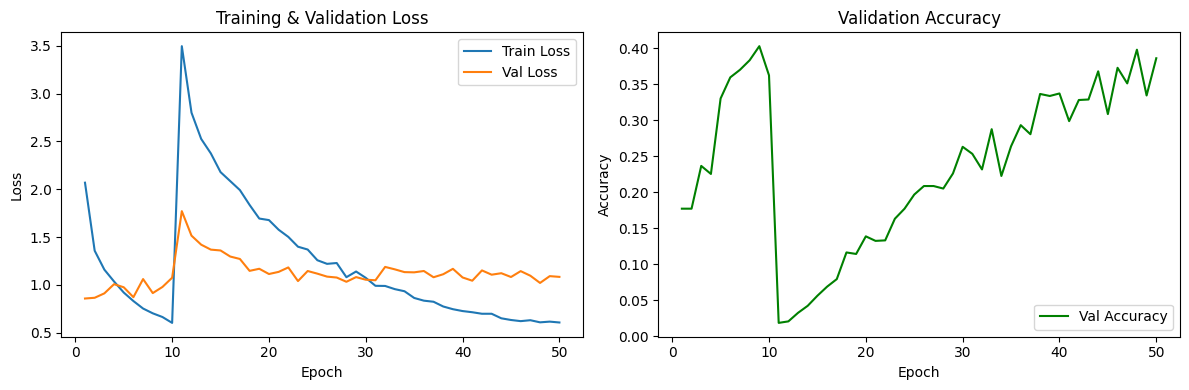

In [1]:
# ===================== CELL 1: TRAIN EfficientCapsNet ON HAM10000 =====================
# Run from inside "CV Lab Project/".   pip install torch torchvision pandas numpy scikit-learn matplotlib seaborn pillow
# Leakage controls: lesion-grouped train/val/test split of HAM10000; class weights + oversampling + augmentation
# from the train split only; best epoch chosen on val only; ISIC2019 duplicates of HAM10000 removed for later cells.
import time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, roc_curve, auc,
                             balanced_accuracy_score, average_precision_score)
from sklearn.preprocessing import label_binarize

# ---- paths
BASE_DIR  = Path.cwd()
DATA_DIR  = BASE_DIR / "data"
HAM_CSV   = DATA_DIR / "HAM10000_metadata.csv"
HAM_IMGS  = DATA_DIR / "images"
ISIC_DIR  = DATA_DIR / "ISIC2019_Dataset"
MODEL_DIR = BASE_DIR / "models"; OUT_DIR = BASE_DIR / "research_results"
MODEL_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
CKPT_PATH = MODEL_DIR / "efficientcapsnet_ham_best.pth"

# ---- config (paper, Table 2)
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]; C = len(CLASSES)
IMG_SIZE, BATCH_SIZE, EPOCHS = 224, 6, 50
STAGE1_END, STAGE2_END = 10, 30
LR_HEAD, LR_FT = 3e-4, 1e-5
ROUTING_ITERS, LAMBDA_ROUTE, FOCAL_GAMMA, LOGIT_SCALE = 3, 0.5, 2.0, 10.0
SEED, NUM_WORKERS = 42, 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

# ---- data
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}
ham = pd.read_csv(HAM_CSV)
_p = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
ham = ham[ham["image_id"].isin(_p)].copy()
ham["path"] = ham["image_id"].map(_p); ham["label"] = ham["dx"]
ham["group"] = ham["lesion_id"].astype(str); ham["y"] = ham["label"].map(CLS_IDX)
ham = ham[["image_id", "path", "label", "group", "y"]].reset_index(drop=True)
print("HAM10000:", len(ham)); print(ham["label"].value_counts())

ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df", "MEL": "mel", "NV": "nv", "VASC": "vasc"}  # SCC dropped
def build_isic_deduped():
    rows = [(p.stem, str(p), dx) for f, dx in ISIC_FOLDER_TO_DX.items() for p in (ISIC_DIR / f).rglob("*.jpg")]
    d = pd.DataFrame(rows, columns=["image_id", "path", "label"]); n0 = len(d)
    d = d[~d["image_id"].isin(set(ham["image_id"]))].reset_index(drop=True)   # remove HAM10000 duplicates
    d["y"] = d["label"].map(CLS_IDX)
    print(f"ISIC2019: {n0} -> {len(d)} after removing {n0 - len(d)} HAM10000 duplicates"); return d

sg = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_i, test_i = next(sg.split(ham, ham["y"], ham["group"]))
trval, test_df = ham.iloc[trval_i].reset_index(drop=True), ham.iloc[test_i].reset_index(drop=True)
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(sg2.split(trval, trval["y"], trval["group"]))
train_df, val_df = trval.iloc[tr_i].reset_index(drop=True), trval.iloc[va_i].reset_index(drop=True)
assert not (set(train_df.group) & set(val_df.group)) and not (set(train_df.group) & set(test_df.group)) \
   and not (set(val_df.group) & set(test_df.group)), "lesion leakage!"
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)} (no shared lesions)")

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
gray = transforms.Grayscale(num_output_channels=3)
train_tf = transforms.Compose([gray, transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=30, translate=(0.2, 0.2), scale=(0.8, 1.2), shear=11),
    transforms.ColorJitter(brightness=(0.9, 1.1)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([gray, transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class LesionDS(Dataset):
    def __init__(self, df, tf): self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]; return self.tf(Image.open(r["path"]).convert("RGB")), int(r["y"])

# ---- model
def squash(s, dim=-1, eps=1e-8):
    n2 = (s ** 2).sum(dim, keepdim=True); return (n2 / (1 + n2)) * s / torch.sqrt(n2 + eps)   # Eq. (1)

class CapsuleHead(nn.Module):
    def __init__(self, in_ch, class_weights, prim_caps_ch=32, prim_dim=8, out_dim=16, grid=7, iters=ROUTING_ITERS, lam=LAMBDA_ROUTE):
        super().__init__()
        self.prim_dim, self.iters, self.lam = prim_dim, iters, lam
        self.proj = nn.Sequential(nn.Conv2d(in_ch, prim_caps_ch * prim_dim, 1), nn.ReLU())
        self.n_in = prim_caps_ch * grid * grid
        self.W = nn.Parameter(0.05 * torch.randn(self.n_in, C, out_dim, prim_dim))
        self.register_buffer("log_cw", torch.log(class_weights))
    def forward(self, f):
        B = f.size(0); p = self.proj(f)
        p = p.view(B, -1, self.prim_dim, p.size(2), p.size(3))
        u = squash(p.permute(0, 1, 3, 4, 2).reshape(B, -1, self.prim_dim))
        u_hat = torch.einsum("jcdk,bjk->bjcd", self.W, u)
        b = torch.zeros(B, self.n_in, C, device=f.device)
        for _ in range(self.iters):
            c = F.softmax(b + self.lam * self.log_cw, dim=2)                 # imbalance-aware routing logits
            v = squash((c.unsqueeze(-1) * u_hat).sum(1))
            b = b + (u_hat * v.unsqueeze(1)).sum(-1)
        return v.norm(dim=-1)

class EfficientCapsNet(nn.Module):
    def __init__(self, class_weights):
        super().__init__()
        self.features = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1).features
        self.head = CapsuleHead(1280, class_weights)
    def forward(self, x): return self.head(self.features(x))

class WeightedFocalLoss(nn.Module):
    def __init__(self, class_weights, gamma=FOCAL_GAMMA):
        super().__init__(); self.register_buffer("w", class_weights); self.gamma = gamma
    def forward(self, norms, y):
        logpt = F.log_softmax(norms * LOGIT_SCALE, 1).gather(1, y[:, None]).squeeze(1)
        return (-self.w[y] * (1 - logpt.exp()) ** self.gamma * logpt).mean()

def set_train_mode(model, stage):
    model.train(); model.features.eval()
    if stage >= 2:
        for blk in model.features[-2:]: blk.train()

@torch.no_grad()
def predict(model, df):
    model.eval(); ys, ps = [], []
    for x, y in DataLoader(LesionDS(df, eval_tf), BATCH_SIZE, num_workers=NUM_WORKERS):
        ps.append(F.softmax(model(x.to(DEVICE)) * LOGIT_SCALE, 1).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def report(title, y, prob):
    pred = prob.argmax(1)
    print("\n" + "=" * 70 + f"\n{title} (n={len(y)})\n" + "=" * 70)
    print("Accuracy:", round(accuracy_score(y, pred), 4), "| Balanced acc:", round(balanced_accuracy_score(y, pred), 4))
    print(classification_report(y, pred, labels=range(C), target_names=CLASSES, digits=4, zero_division=0))
    safe = "".join(ch if ch.isalnum() else "_" for ch in title)
    plt.figure(figsize=(8, 6)); sns.heatmap(confusion_matrix(y, pred, labels=range(C)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title(f"Confusion Matrix - {title}"); plt.tight_layout()
    plt.savefig(OUT_DIR / f"ecn_{safe}_confusion.png", dpi=200); plt.show()
    yb = label_binarize(y, classes=range(C)); plt.figure(figsize=(8, 6))
    for i, c in enumerate(CLASSES):
        if yb[:, i].sum() == 0: continue
        fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
        print(f"{c}: AP = {average_precision_score(yb[:, i], prob[:, i]):.4f}")
    plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"Multiclass ROC - {title}"); plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(OUT_DIR / f"ecn_{safe}_roc.png", dpi=200); plt.show()

# ---- training (Algorithm 1, 3-stage transfer learning)
counts = train_df["y"].value_counts().reindex(range(C)).values.astype(float)
cw = torch.tensor(len(train_df) / (C * counts), dtype=torch.float32)          # Cw = N / (C * Nc), train only
print("Class weights:", dict(zip(CLASSES, cw.numpy().round(4))))
sampler = WeightedRandomSampler((1.0 / np.sqrt(counts))[train_df["y"].values], num_samples=len(train_df), replacement=True)
train_loader = DataLoader(LesionDS(train_df, train_tf), BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(LesionDS(val_df, eval_tf), BATCH_SIZE, num_workers=NUM_WORKERS)

model = EfficientCapsNet(cw.to(DEVICE)).to(DEVICE)
criterion = WeightedFocalLoss(cw.to(DEVICE)).to(DEVICE)
for p in model.features.parameters(): p.requires_grad = False
optimizer = torch.optim.AdamW(model.head.parameters(), lr=LR_HEAD)           # Stage 1
history = {"tr_loss": [], "val_loss": [], "val_acc": []}; best_acc, stage = 0.0, 1
for epoch in range(1, EPOCHS + 1):
    if epoch == STAGE1_END + 1:                                              # Stage 2: unfreeze last two blocks
        stage = 2
        for blk in model.features[-2:]:
            for p in blk.parameters(): p.requires_grad = True
        optimizer = torch.optim.AdamW(list(model.head.parameters()) + [p for blk in model.features[-2:] for p in blk.parameters()], lr=LR_FT)
    elif epoch == STAGE2_END + 1:
        stage = 3
    set_train_mode(model, stage); t0, run = time.time(), 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(model(x), y); loss.backward(); optimizer.step()
        run += loss.item() * x.size(0)
    tr_loss = run / len(train_df)
    model.eval(); vl, correct = 0.0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE); o = model(x)
            vl += criterion(o, y).item() * x.size(0); correct += (o.argmax(1) == y).sum().item()
    val_loss, val_acc = vl / len(val_df), correct / len(val_df)
    history["tr_loss"].append(tr_loss); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    flag = ""
    if val_acc > best_acc: best_acc = val_acc; torch.save(model.state_dict(), CKPT_PATH); flag = " *saved*"
    print(f"[Stage {stage}] Epoch {epoch:02d}/{EPOCHS} | train {tr_loss:.4f} | val {val_loss:.4f} | val_acc {val_acc:.4f} | {time.time()-t0:.0f}s{flag}")

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE)); model.eval()
ep = range(1, len(history["tr_loss"]) + 1); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["tr_loss"], label="Train Loss"); ax[0].plot(ep, history["val_loss"], label="Val Loss")
ax[0].set_title("Training & Validation Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
ax[1].plot(ep, history["val_acc"], color="green", label="Val Accuracy"); ax[1].set_title("Validation Accuracy")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "ecn_accuracy_loss_curves.png", dpi=200); plt.show()


ISIC2019: 24703 -> 14885 after removing 9818 HAM10000 duplicates
label
nv       6170
mel      3409
bcc      2809
bkl      1525
akiec     737
df        124
vasc      111
Name: count, dtype: int64

ISIC2019 external test (HAM-trained) (n=14885)
Accuracy: 0.2887 | Balanced acc: 0.2857
              precision    recall  f1-score   support

       akiec     0.0957    0.1940    0.1281       737
         bcc     0.3983    0.4397    0.4179      2809
         bkl     0.1660    0.2846    0.2097      1525
          df     0.0263    0.1532    0.0449       124
         mel     0.3042    0.4503    0.3631      3409
          nv     0.7842    0.1449    0.2446      6170
        vasc     0.0483    0.3333    0.0844       111

    accuracy                         0.2887     14885
   macro avg     0.2604    0.2857    0.2132     14885
weighted avg     0.4922    0.2887    0.2922     14885



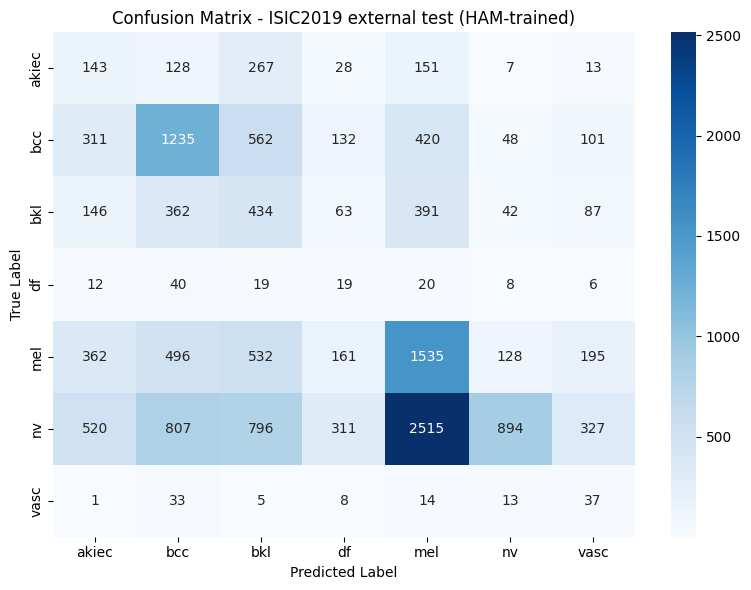

akiec: AP = 0.0675
bcc: AP = 0.3650
bkl: AP = 0.1425
df: AP = 0.0192
mel: AP = 0.3133
nv: AP = 0.6764
vasc: AP = 0.0687


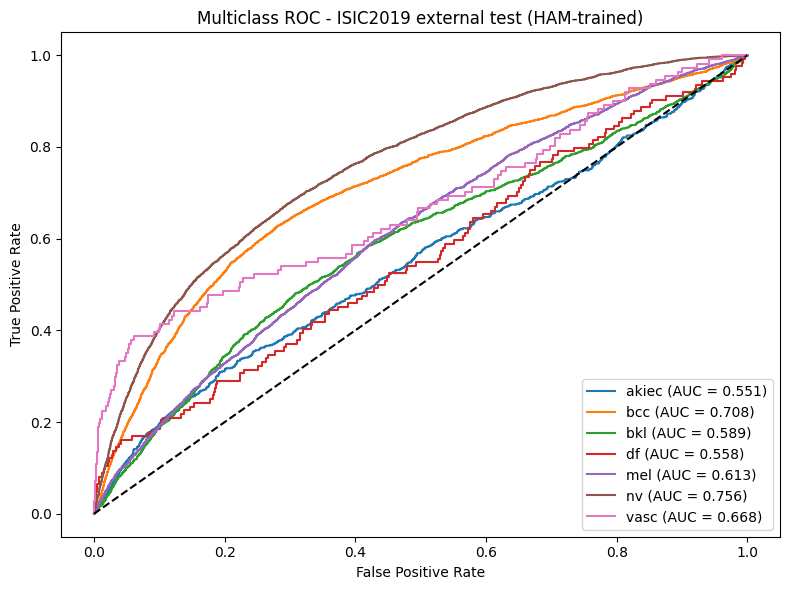

In [2]:
# ===================== CELL 2: TEST ON ISIC2019 (external; HAM10000 duplicates removed) =====================
isic_df = build_isic_deduped(); print(isic_df["label"].value_counts())
y_isic, p_isic = predict(model, isic_df)
report("ISIC2019 external test (HAM-trained)", y_isic, p_isic)


ISIC2019: 24703 -> 14885 after removing 9818 HAM10000 duplicates

HAM10000 held-out test (in-dataset) (n=1431)
Accuracy: 0.4053 | Balanced acc: 0.4664
              precision    recall  f1-score   support

       akiec     0.1286    0.3913    0.1935        46
         bcc     0.2660    0.6757    0.3817        74
         bkl     0.2812    0.2866    0.2839       157
          df     0.0909    0.3529    0.1446        17
         mel     0.1958    0.5283    0.2857       159
          nv     0.9707    0.3800    0.5461       958
        vasc     0.1781    0.6500    0.2796        20

    accuracy                         0.4053      1431
   macro avg     0.3016    0.4664    0.3022      1431
weighted avg     0.7239    0.4053    0.4601      1431



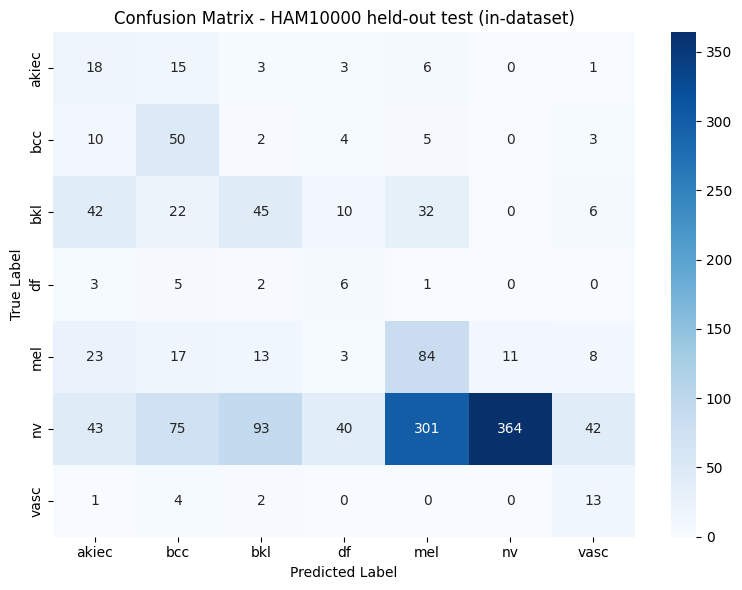

akiec: AP = 0.1613
bcc: AP = 0.4022
bkl: AP = 0.2487
df: AP = 0.1430
mel: AP = 0.1758
nv: AP = 0.9282
vasc: AP = 0.3063


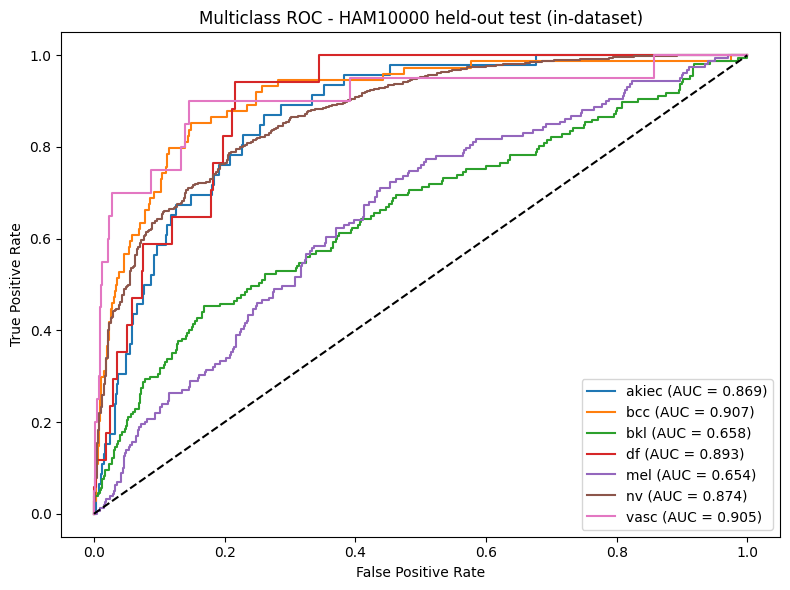


Combined HAM-test + ISIC2019 (n=16316)
Accuracy: 0.2989 | Balanced acc: 0.3036
              precision    recall  f1-score   support

       akiec     0.0985    0.2056    0.1332       783
         bcc     0.3907    0.4457    0.4164      2883
         bkl     0.1726    0.2848    0.2149      1682
          df     0.0317    0.1773    0.0538       141
         mel     0.2957    0.4538    0.3581      3568
          nv     0.8304    0.1765    0.2911      7128
        vasc     0.0596    0.3817    0.1031       131

    accuracy                         0.2989     16316
   macro avg     0.2685    0.3036    0.2244     16316
weighted avg     0.5197    0.2989    0.3089     16316



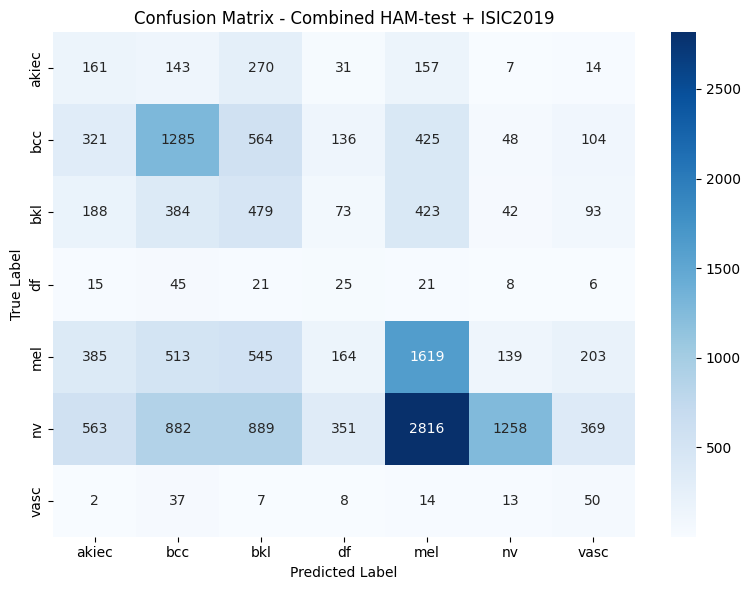

akiec: AP = 0.0714
bcc: AP = 0.3606
bkl: AP = 0.1488
df: AP = 0.0241
mel: AP = 0.3003
nv: AP = 0.7203
vasc: AP = 0.0880


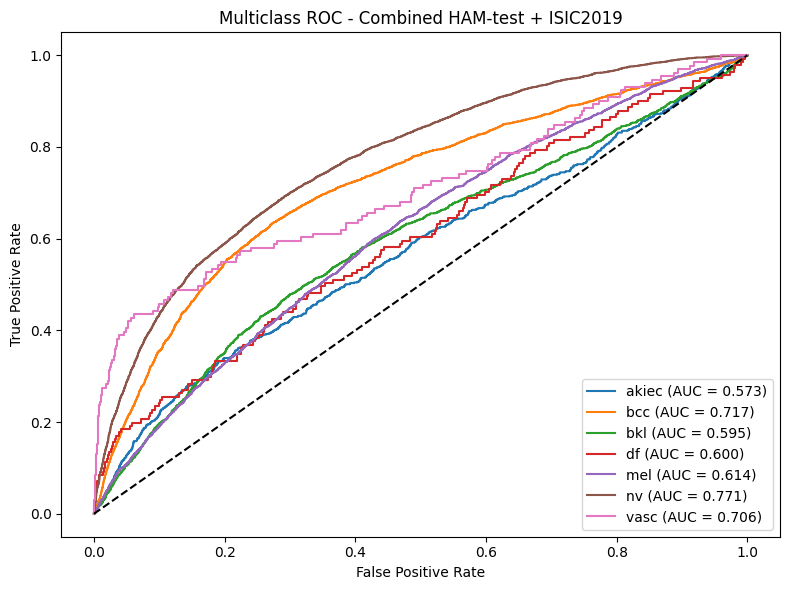

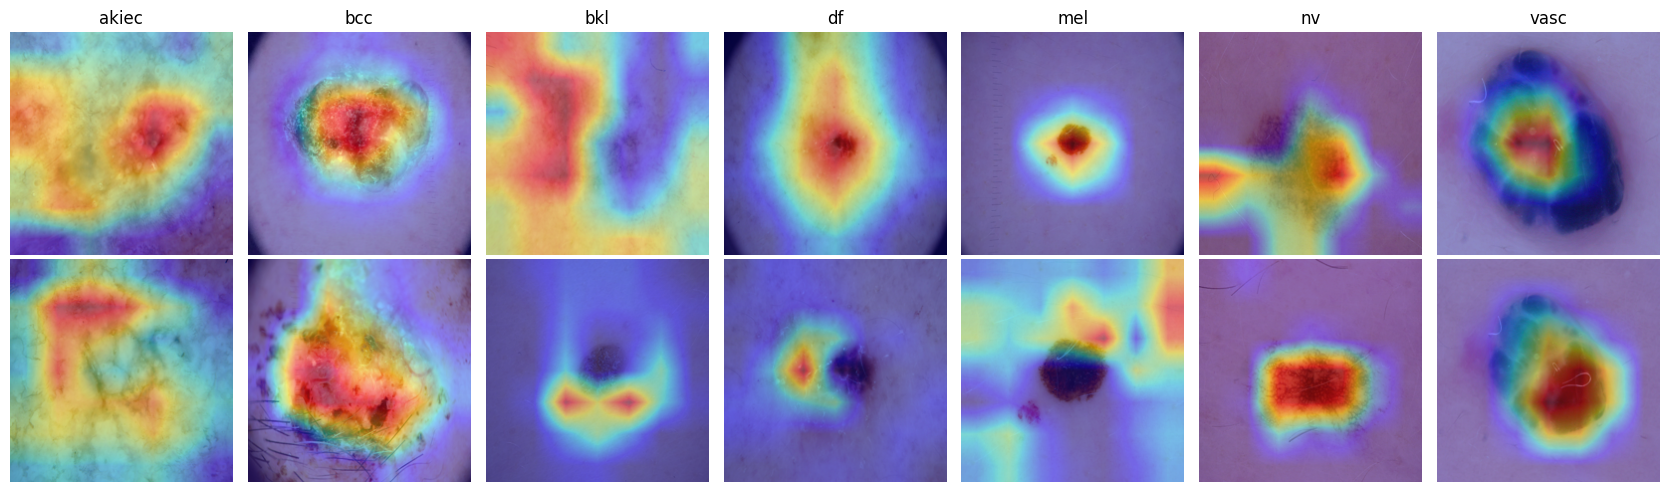

In [3]:
# ===================== CELL 3: TEST ON COMBINED (HAM10000 held-out test + ISIC2019) =====================
isic_df = build_isic_deduped()
if "p_isic" not in globals(): y_isic, p_isic = predict(model, isic_df)
y_ham, p_ham = predict(model, test_df)
report("HAM10000 held-out test (in-dataset)", y_ham, p_ham)
report("Combined HAM-test + ISIC2019", np.concatenate([y_ham, y_isic]), np.concatenate([p_ham, p_isic]))

# Grad-CAM samples (last EfficientNet block) from the combined test set
comb_df = pd.concat([test_df, isic_df], ignore_index=True)
acts, grads = {}, {}; layer = model.features[-1]
h1 = layer.register_forward_hook(lambda m, i, o: acts.update(a=o))
h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
fig, axs = plt.subplots(2, C, figsize=(2.4 * C, 5))
for j, cls in enumerate(CLASSES):
    for i, (_, r) in enumerate(comb_df[comb_df["label"] == cls].head(2).iterrows()):
        img = Image.open(r["path"]).convert("RGB"); x = eval_tf(img).unsqueeze(0).to(DEVICE).requires_grad_(True)
        out = model(x); model.zero_grad(); out[0, out.argmax()].backward()
        w = grads["g"].mean((2, 3), keepdim=True); cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
        cam = F.interpolate(cam, (IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        axs[i, j].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axs[i, j].imshow(cam, cmap="jet", alpha=0.45); axs[i, j].axis("off"); axs[0, j].set_title(cls)
h1.remove(); h2.remove(); plt.tight_layout(); plt.savefig(OUT_DIR / "ecn_gradcam_sample.png", dpi=200); plt.show()
